Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE INFORMATION
GPU detected: Tesla T4
GPU Memory: 14.56 GB
Using device: cuda

ZIP file found:
/content/drive/MyDrive/NeuroScreen/datasets/FER2013.zip
ZIP size: 0.06 GB

EXTRACTING DATASET TO LOCAL COLAB STORAGE
Removing previous local dataset...
Extraction completed in 0.06 minutes.

SEARCHING DATASET STRUCTURE
Train directory:
/content/FER2013/train

Test directory:
/content/FER2013/test

DATASET CLASSES
Classes:
0: angry
1: disgust
2: fear
3: happy
4: neutral
5: sad
6: surprise

Number of classes: 7

LOADING TRAINING DATA
Total training images: 28709

Dataset split:
Training:   22,968
Validation: 5,741
Test:       7,178

CREATING DATA LOADERS
DataLoaders ready.

CREATING EFFICIENTNET-B0
Model: efficientnet_b0
Number of classes: 7

CHECKPOINT FOUND
Loading: /content/drive/MyDrive/NeuroScreen/checkpoints/emotion_checkpoint.pth
Resuming from epoch 10
Best

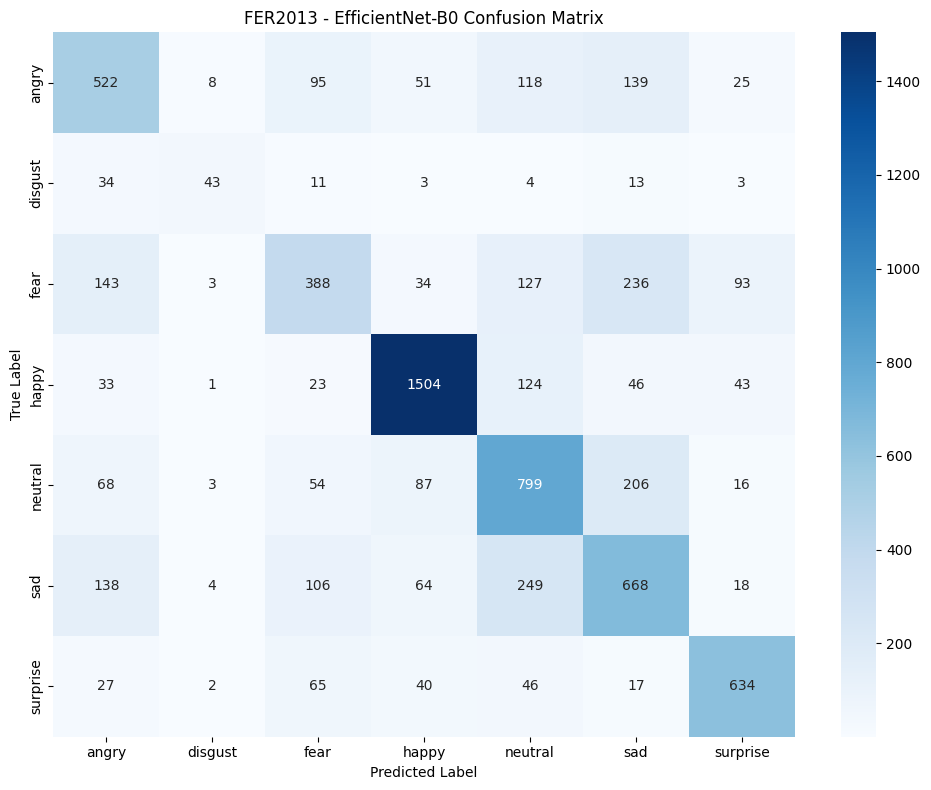

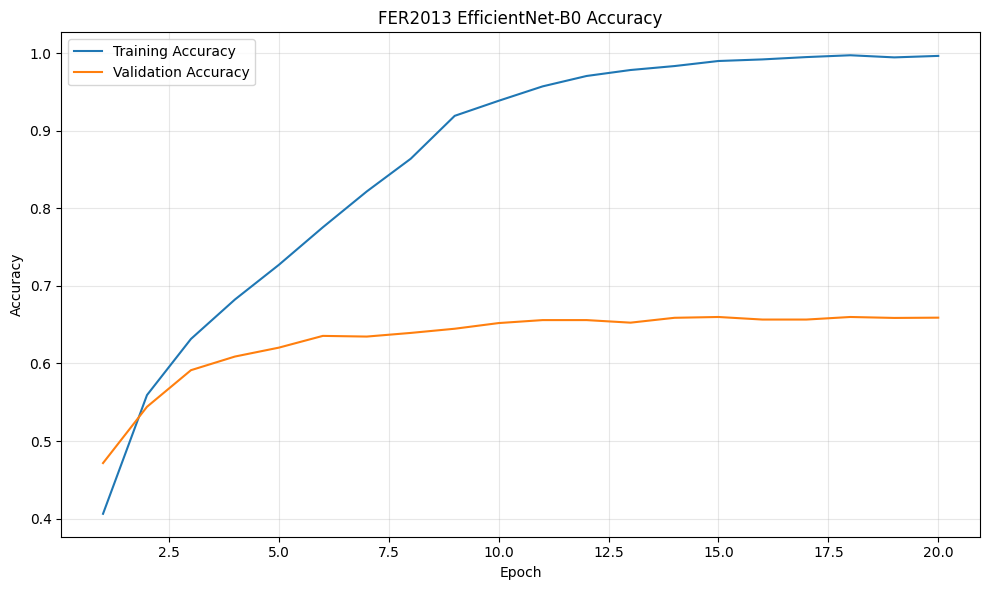

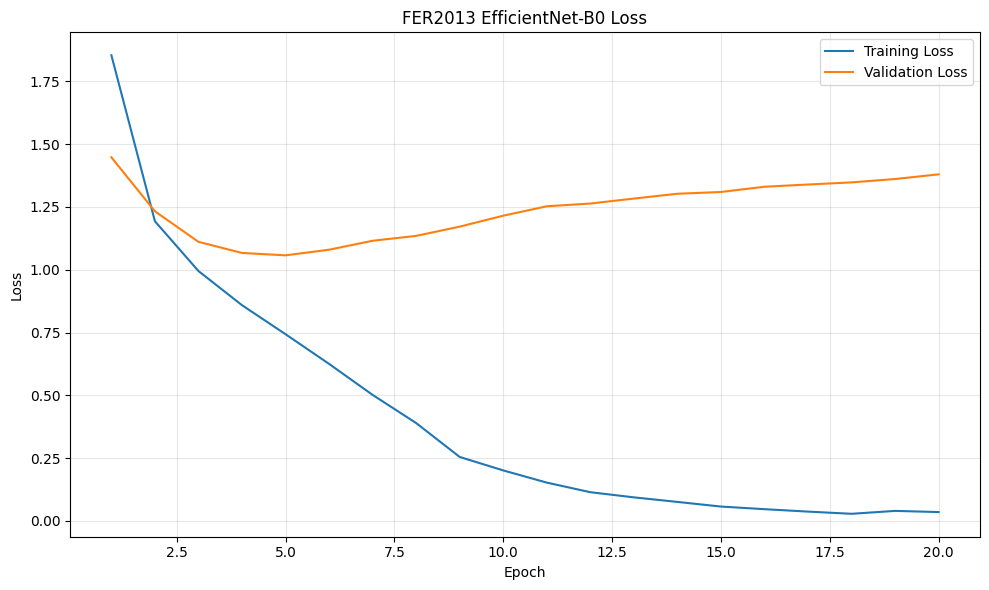


NEUROSCREEN FER2013 TRAINING SUMMARY
Model: EfficientNet-B0
Classes: 7
Epochs completed: 20
Best validation accuracy: 62.04%
Final test accuracy: 63.50%
Test weighted F1: 63.19%

Saved files:

Checkpoint:
/content/drive/MyDrive/NeuroScreen/checkpoints/emotion_checkpoint.pth

Best model:
/content/drive/MyDrive/NeuroScreen/models/emotion_best.pth

Training history:
/content/drive/MyDrive/NeuroScreen/results/emotion_training_history.csv

Classification report:
/content/drive/MyDrive/NeuroScreen/results/emotion_classification_report.txt

Confusion matrix:
/content/drive/MyDrive/NeuroScreen/results/emotion_confusion_matrix.png

Metrics:
/content/drive/MyDrive/NeuroScreen/results/emotion_final_metrics.json

IMPORTANT FOR THE NEXT COLAB SESSION

Simply run this same cell again.

The code will:
1. Mount Google Drive.
2. Extract FER2013 ZIP to /content.
3. Recreate the same train/validation split.
4. Load emotion_checkpoint.pth.
5. Detect the last completed epoch.
6. Continue for another 10 ep

In [ ]:
# ============================================================
# NeuroScreen - FER2013 Emotion Detection
# EfficientNet-B0 | Google Colab T4
#
# TRAINING STRATEGY:
#   - Dataset ZIP stored in Google Drive
#   - Dataset extracted to local Colab storage (/content)
#   - Train / Validation / Test split
#   - 10 epochs per Colab session
#   - Automatically resumes from checkpoint
#   - Checkpoints + results stored permanently in Google Drive
# ============================================================


# ============================================================
# 1. INSTALL REQUIRED LIBRARIES
# ============================================================

!pip -q install timm scikit-learn seaborn


# ============================================================
# 2. IMPORTS
# ============================================================

import os
import zipfile
import shutil
import random
import json
import time
import copy
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support
)

from google.colab import drive


# ============================================================
# 3. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')


# ============================================================
# 4. CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# Google Drive locations
# ------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/NeuroScreen"

DATASET_DIR = os.path.join(DRIVE_ROOT, "datasets")
CHECKPOINT_DIR = os.path.join(DRIVE_ROOT, "checkpoints")
MODEL_DIR = os.path.join(DRIVE_ROOT, "models")
RESULTS_DIR = os.path.join(DRIVE_ROOT, "results")


# ------------------------------------------------------------
# IMPORTANT:
# Change only this filename if your ZIP has a different name.
# ------------------------------------------------------------

ZIP_PATH = os.path.join(DATASET_DIR, "FER2013.zip")


# ------------------------------------------------------------
# Local Colab extraction directory
# ------------------------------------------------------------

LOCAL_DATASET_DIR = "/content/FER2013"


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

MODEL_NAME = "efficientnet_b0"

IMAGE_SIZE = 224
BATCH_SIZE = 64

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

# Number of epochs PER COLAB SESSION
EPOCHS_PER_SESSION = 10

# Validation percentage taken from TRAIN directory
VALIDATION_SPLIT = 0.20

RANDOM_SEED = 42

NUM_WORKERS = 2

# Save checkpoint after every epoch
SAVE_EVERY_EPOCH = True


# ============================================================
# 5. CREATE REQUIRED DRIVE DIRECTORIES
# ============================================================

os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)


# ============================================================
# 6. CHECK GPU
# ============================================================

print("=" * 70)
print("DEVICE INFORMATION")
print("=" * 70)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU detected:", torch.cuda.get_device_name(0))

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        f"GPU Memory: "
        f"{gpu_properties.total_memory / (1024 ** 3):.2f} GB"
    )
else:
    DEVICE = torch.device("cpu")
    print("WARNING: GPU not detected.")
    print("Training will be extremely slow.")

print("Using device:", DEVICE)

print("=" * 70)


# ============================================================
# 7. REPRODUCIBILITY
# ============================================================

def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(RANDOM_SEED)


# ============================================================
# 8. CHECK ZIP FILE
# ============================================================

if not os.path.exists(ZIP_PATH):

    raise FileNotFoundError(
        f"""
FER2013 ZIP file was not found.

Expected location:
{ZIP_PATH}

Please upload/copy your FER2013 ZIP to:

MyDrive/
└── NeuroScreen/
    └── datasets/
        └── FER2013.zip
"""
    )

print("\nZIP file found:")
print(ZIP_PATH)

zip_size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)

print(f"ZIP size: {zip_size_gb:.2f} GB")


# ============================================================
# 9. EXTRACT ZIP TO LOCAL COLAB STORAGE
# ============================================================

print("\n" + "=" * 70)
print("EXTRACTING DATASET TO LOCAL COLAB STORAGE")
print("=" * 70)

# Remove previous local extraction
if os.path.exists(LOCAL_DATASET_DIR):

    print("Removing previous local dataset...")

    shutil.rmtree(LOCAL_DATASET_DIR)


os.makedirs(LOCAL_DATASET_DIR, exist_ok=True)


start_extract = time.time()

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    zip_ref.extractall(LOCAL_DATASET_DIR)


extract_time = time.time() - start_extract

print(
    f"Extraction completed in "
    f"{extract_time / 60:.2f} minutes."
)


# ============================================================
# 10. FIND ACTUAL TRAIN / TEST DIRECTORIES
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING DATASET STRUCTURE")
print("=" * 70)


def find_directory(root, directory_name):

    matches = []

    for current_root, dirs, files in os.walk(root):

        for directory in dirs:

            if directory.lower() == directory_name.lower():

                matches.append(
                    os.path.join(current_root, directory)
                )

    return matches


train_candidates = find_directory(
    LOCAL_DATASET_DIR,
    "train"
)

test_candidates = find_directory(
    LOCAL_DATASET_DIR,
    "test"
)


if len(train_candidates) == 0:

    raise FileNotFoundError(
        """
Could not find a 'train' directory inside the extracted FER2013 dataset.

Please inspect the ZIP structure.
"""
    )


if len(test_candidates) == 0:

    raise FileNotFoundError(
        """
Could not find a 'test' directory inside the extracted FER2013 dataset.

Please inspect the ZIP structure.
"""
    )


# Usually there will be one train and one test directory.
TRAIN_DIR = train_candidates[0]
TEST_DIR = test_candidates[0]


print("Train directory:")
print(TRAIN_DIR)

print("\nTest directory:")
print(TEST_DIR)


# ============================================================
# 11. DISPLAY DATASET STRUCTURE
# ============================================================

print("\n" + "=" * 70)
print("DATASET CLASSES")
print("=" * 70)


classes_found = sorted([
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, d))
])


print("Classes:")

for i, class_name in enumerate(classes_found):

    print(f"{i}: {class_name}")


NUM_CLASSES = len(classes_found)

print("\nNumber of classes:", NUM_CLASSES)


# ============================================================
# 12. DATA TRANSFORMS
# ============================================================

# Training augmentation
train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation/test transform
eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 13. LOAD FULL TRAINING DATASET
# ============================================================

print("\n" + "=" * 70)
print("LOADING TRAINING DATA")
print("=" * 70)


# We initially load using evaluation transform.
# After splitting, separate transform datasets will be created.

full_train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=eval_transform
)


print(
    "Total training images:",
    len(full_train_dataset)
)


# ============================================================
# 14. TRAIN / VALIDATION SPLIT
# ============================================================

total_size = len(full_train_dataset)

validation_size = int(
    total_size * VALIDATION_SPLIT
)

training_size = total_size - validation_size


generator = torch.Generator()

generator.manual_seed(
    RANDOM_SEED
)


train_subset, validation_subset = random_split(
    full_train_dataset,
    [training_size, validation_size],
    generator=generator
)


# ============================================================
# 15. APPLY DIFFERENT TRANSFORMS TO TRAIN / VALIDATION
# ============================================================

# Create a fresh ImageFolder for training augmentation
train_full_augmented = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

# Create a fresh ImageFolder for validation
validation_full_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=eval_transform
)


# Reuse exactly the same indices
train_dataset = torch.utils.data.Subset(
    train_full_augmented,
    train_subset.indices
)

validation_dataset = torch.utils.data.Subset(
    validation_full_dataset,
    validation_subset.indices
)


# ============================================================
# 16. LOAD OFFICIAL TEST DATASET
# ============================================================

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=eval_transform
)


print("\nDataset split:")
print(
    f"Training:   {len(train_dataset):,}"
)

print(
    f"Validation: {len(validation_dataset):,}"
)

print(
    f"Test:       {len(test_dataset):,}"
)


# ============================================================
# 17. CREATE DATA LOADERS
# ============================================================

print("\n" + "=" * 70)
print("CREATING DATA LOADERS")
print("=" * 70)


pin_memory = torch.cuda.is_available()


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory,

    persistent_workers=(
        NUM_WORKERS > 0
    )
)


validation_loader = DataLoader(

    validation_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory,

    persistent_workers=(
        NUM_WORKERS > 0
    )
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory,

    persistent_workers=(
        NUM_WORKERS > 0
    )
)


print("DataLoaders ready.")


# ============================================================
# 18. CREATE EFFICIENTNET-B0
# ============================================================

print("\n" + "=" * 70)
print("CREATING EFFICIENTNET-B0")
print("=" * 70)


model = timm.create_model(

    MODEL_NAME,

    pretrained=True,

    num_classes=NUM_CLASSES
)


model = model.to(DEVICE)


print(
    f"Model: {MODEL_NAME}"
)

print(
    f"Number of classes: {NUM_CLASSES}"
)


# ============================================================
# 19. LOSS FUNCTION
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# 20. OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 21. LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=0.5,

    patience=2
)


# ============================================================
# 22. MIXED PRECISION
# ============================================================

if torch.cuda.is_available():

    scaler = torch.amp.GradScaler(
        "cuda"
    )

else:

    scaler = None


# ============================================================
# 23. CHECKPOINT PATHS
# ============================================================

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "emotion_checkpoint.pth"
)


BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "emotion_best.pth"
)


HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_training_history.csv"
)


CLASS_NAMES_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_class_names.json"
)


# ============================================================
# 24. SAVE CLASS NAMES
# ============================================================

with open(
    CLASS_NAMES_PATH,
    "w"
) as f:

    json.dump(
        full_train_dataset.classes,
        f,
        indent=4
    )


# ============================================================
# 25. INITIAL TRAINING STATE
# ============================================================

start_epoch = 0

best_validation_loss = float("inf")

best_validation_accuracy = 0.0

training_history = []


# ============================================================
# 26. LOAD PREVIOUS CHECKPOINT IF AVAILABLE
# ============================================================

if os.path.exists(CHECKPOINT_PATH):

    print("\n" + "=" * 70)
    print("CHECKPOINT FOUND")
    print("=" * 70)

    print(
        "Loading:",
        CHECKPOINT_PATH
    )


    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE
    )


    # --------------------------------------------------------
    # Load model
    # --------------------------------------------------------

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )


    # --------------------------------------------------------
    # Load optimizer
    # --------------------------------------------------------

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )


    # --------------------------------------------------------
    # Load scheduler
    # --------------------------------------------------------

    if "scheduler_state_dict" in checkpoint:

        scheduler.load_state_dict(
            checkpoint["scheduler_state_dict"]
        )


    # --------------------------------------------------------
    # Load AMP scaler
    # --------------------------------------------------------

    if (
        scaler is not None
        and "scaler_state_dict" in checkpoint
        and checkpoint["scaler_state_dict"] is not None
    ):

        scaler.load_state_dict(
            checkpoint["scaler_state_dict"]
        )


    # --------------------------------------------------------
    # Resume epoch
    # --------------------------------------------------------

    start_epoch = checkpoint.get(
        "epoch",
        0
    )


    # --------------------------------------------------------
    # Best validation loss
    # --------------------------------------------------------

    best_validation_loss = checkpoint.get(
        "best_validation_loss",
        float("inf")
    )


    # --------------------------------------------------------
    # Best validation accuracy
    # --------------------------------------------------------

    best_validation_accuracy = checkpoint.get(
        "best_validation_accuracy",
        0.0
    )


    # --------------------------------------------------------
    # Load history
    # --------------------------------------------------------

    training_history = checkpoint.get(
        "history",
        []
    )


    print(
        f"Resuming from epoch "
        f"{start_epoch}"
    )

    print(
        f"Best validation loss: "
        f"{best_validation_loss:.4f}"
    )

    print(
        f"Best validation accuracy: "
        f"{best_validation_accuracy:.4f}"
    )


else:

    print("\nNo previous checkpoint found.")

    print(
        "Starting training from epoch 1."
    )


# ============================================================
# 27. DETERMINE THIS SESSION'S END EPOCH
# ============================================================

end_epoch = (
    start_epoch +
    EPOCHS_PER_SESSION
)


print("\n" + "=" * 70)
print("TRAINING PLAN")
print("=" * 70)

print(
    f"Previous completed epochs: "
    f"{start_epoch}"
)

print(
    f"This session: "
    f"epochs {start_epoch + 1} "
    f"to {end_epoch}"
)

print(
    f"Total epochs after session: "
    f"{end_epoch}"
)

print("=" * 70)


# ============================================================
# 28. TRAINING FUNCTION
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        if scaler is not None:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )


            scaler.scale(
                loss
            ).backward()


            scaler.step(
                optimizer
            )


            scaler.update()


        else:

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        _, predictions = torch.max(
            outputs,
            1
        )


        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()


    epoch_loss = (
        running_loss /
        total
    )


    epoch_accuracy = (
        correct /
        total
    )


    return (
        epoch_loss,
        epoch_accuracy
    )


# ============================================================
# 29. VALIDATION FUNCTION
# ============================================================

def validate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0


    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            # Mixed precision inference
            if torch.cuda.is_available():

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16
                ):

                    outputs = model(images)

                    loss = criterion(
                        outputs,
                        labels
                    )

            else:

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )


            running_loss += (
                loss.item()
                * images.size(0)
            )


            _, predictions = torch.max(
                outputs,
                1
            )


            total += labels.size(0)

            correct += (
                predictions == labels
            ).sum().item()


    epoch_loss = (
        running_loss /
        total
    )


    epoch_accuracy = (
        correct /
        total
    )


    return (
        epoch_loss,
        epoch_accuracy
    )


# ============================================================
# 30. TRAINING LOOP
# ============================================================

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)


session_start_time = time.time()


for epoch in range(
    start_epoch,
    end_epoch
):

    epoch_number = epoch + 1

    epoch_start_time = time.time()


    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss, train_accuracy = train_one_epoch(

        model=model,

        loader=train_loader,

        criterion=criterion,

        optimizer=optimizer,

        scaler=scaler,

        device=DEVICE
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    validation_loss, validation_accuracy = validate(

        model=model,

        loader=validation_loader,

        criterion=criterion,

        device=DEVICE
    )


    # --------------------------------------------------------
    # Scheduler
    # --------------------------------------------------------

    scheduler.step(
        validation_loss
    )


    current_lr = optimizer.param_groups[0]["lr"]


    epoch_time = (
        time.time() -
        epoch_start_time
    )


    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history_row = {

        "epoch": epoch_number,

        "train_loss": train_loss,

        "train_accuracy": train_accuracy,

        "validation_loss": validation_loss,

        "validation_accuracy": validation_accuracy,

        "learning_rate": current_lr,

        "epoch_time_seconds": epoch_time
    }


    training_history.append(
        history_row
    )


    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print(
        f"\nEpoch "
        f"{epoch_number}/{end_epoch}"
    )

    print(
        f"Train Loss: "
        f"{train_loss:.4f}"
    )

    print(
        f"Train Accuracy: "
        f"{train_accuracy * 100:.2f}%"
    )

    print(
        f"Validation Loss: "
        f"{validation_loss:.4f}"
    )

    print(
        f"Validation Accuracy: "
        f"{validation_accuracy * 100:.2f}%"
    )

    print(
        f"Learning Rate: "
        f"{current_lr:.8f}"
    )

    print(
        f"Epoch Time: "
        f"{epoch_time / 60:.2f} minutes"
    )


    # --------------------------------------------------------
    # Check if best validation model
    # --------------------------------------------------------

    is_best = (
        validation_loss <
        best_validation_loss
    )


    if is_best:

        best_validation_loss = (
            validation_loss
        )

        best_validation_accuracy = (
            validation_accuracy
        )


        torch.save(

            {
                "model_state_dict":
                    model.state_dict(),

                "model_name":
                    MODEL_NAME,

                "num_classes":
                    NUM_CLASSES,

                "class_names":
                    full_train_dataset.classes,

                "image_size":
                    IMAGE_SIZE,

                "validation_loss":
                    validation_loss,

                "validation_accuracy":
                    validation_accuracy,

                "epoch":
                    epoch_number
            },

            BEST_MODEL_PATH
        )


        print(
            "✓ New best model saved."
        )

        print(
            BEST_MODEL_PATH
        )


    # --------------------------------------------------------
    # Save checkpoint
    # --------------------------------------------------------

    if SAVE_EVERY_EPOCH:

        checkpoint = {

            "epoch":
                epoch_number,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "scaler_state_dict":
                (
                    scaler.state_dict()
                    if scaler is not None
                    else None
                ),

            "best_validation_loss":
                best_validation_loss,

            "best_validation_accuracy":
                best_validation_accuracy,

            "history":
                training_history,

            "model_name":
                MODEL_NAME,

            "num_classes":
                NUM_CLASSES,

            "class_names":
                full_train_dataset.classes,

            "image_size":
                IMAGE_SIZE,

            "random_seed":
                RANDOM_SEED
        }


        torch.save(
            checkpoint,
            CHECKPOINT_PATH
        )


        print(
            "✓ Checkpoint saved."
        )


    # --------------------------------------------------------
    # Save history CSV
    # --------------------------------------------------------

    history_df = pd.DataFrame(
        training_history
    )


    history_df.to_csv(
        HISTORY_PATH,
        index=False
    )


# ============================================================
# 31. SESSION COMPLETED
# ============================================================

session_time = (
    time.time() -
    session_start_time
)


print("\n" + "=" * 70)
print("TRAINING SESSION COMPLETED")
print("=" * 70)

print(
    f"Epochs completed in this session: "
    f"{start_epoch + 1} - {end_epoch}"
)

print(
    f"Total training time: "
    f"{session_time / 60:.2f} minutes"
)

print(
    f"Best validation accuracy: "
    f"{best_validation_accuracy * 100:.2f}%"
)

print(
    f"Best validation loss: "
    f"{best_validation_loss:.4f}"
)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

print("\nBest model:")
print(BEST_MODEL_PATH)


# ============================================================
# 32. LOAD BEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("LOADING BEST VALIDATION MODEL")
print("=" * 70)


best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)


model.load_state_dict(
    best_checkpoint["model_state_dict"]
)


model.eval()


print(
    "Best model loaded successfully."
)


# ============================================================
# 33. FINAL TEST EVALUATION
#
# IMPORTANT:
# The official TEST set is used ONLY here.
# It was never used to select the best model.
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)


all_predictions = []

all_labels = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )


        if torch.cuda.is_available():

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

        else:

            outputs = model(images)


        predictions = torch.argmax(
            outputs,
            dim=1
        )


        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )


all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)


# ============================================================
# 34. TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)


precision, recall, f1, _ = (
    precision_recall_fscore_support(

        all_labels,

        all_predictions,

        average="weighted",

        zero_division=0
    )
)


print(
    f"\nTest Accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Weighted Precision: "
    f"{precision * 100:.2f}%"
)

print(
    f"Weighted Recall: "
    f"{recall * 100:.2f}%"
)

print(
    f"Weighted F1 Score: "
    f"{f1 * 100:.2f}%"
)


# ============================================================
# 35. CLASSIFICATION REPORT
# ============================================================

report = classification_report(

    all_labels,

    all_predictions,

    target_names=full_train_dataset.classes,

    digits=4,

    zero_division=0
)


print("\nClassification Report:")
print(report)


REPORT_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_classification_report.txt"
)


with open(
    REPORT_PATH,
    "w"
) as f:

    f.write(report)


# ============================================================
# 36. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    all_labels,

    all_predictions
)


plt.figure(
    figsize=(10, 8)
)


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=full_train_dataset.classes,

    yticklabels=full_train_dataset.classes
)


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "FER2013 - EfficientNet-B0 Confusion Matrix"
)


plt.tight_layout()


CONFUSION_MATRIX_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_confusion_matrix.png"
)


plt.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 37. TRAINING HISTORY GRAPH
# ============================================================

history_df = pd.DataFrame(
    training_history
)


# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)


plt.plot(

    history_df["epoch"],

    history_df["train_accuracy"],

    label="Training Accuracy"
)


plt.plot(

    history_df["epoch"],

    history_df["validation_accuracy"],

    label="Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "FER2013 EfficientNet-B0 Accuracy"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


ACCURACY_GRAPH_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_accuracy_curve.png"
)


plt.savefig(
    ACCURACY_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)


plt.plot(

    history_df["epoch"],

    history_df["train_loss"],

    label="Training Loss"
)


plt.plot(

    history_df["epoch"],

    history_df["validation_loss"],

    label="Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "FER2013 EfficientNet-B0 Loss"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()


LOSS_GRAPH_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_loss_curve.png"
)


plt.savefig(
    LOSS_GRAPH_PATH,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# 38. SAVE FINAL METRICS
# ============================================================

final_metrics = {

    "model":
        MODEL_NAME,

    "dataset":
        "FER2013",

    "num_classes":
        NUM_CLASSES,

    "classes":
        full_train_dataset.classes,

    "epochs_completed":
        end_epoch,

    "best_validation_accuracy":
        best_validation_accuracy,

    "best_validation_loss":
        best_validation_loss,

    "test_accuracy":
        test_accuracy,

    "test_weighted_precision":
        precision,

    "test_weighted_recall":
        recall,

    "test_weighted_f1":
        f1,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "image_size":
        IMAGE_SIZE,

    "validation_split":
        VALIDATION_SPLIT
}


METRICS_PATH = os.path.join(
    RESULTS_DIR,
    "emotion_final_metrics.json"
)


with open(
    METRICS_PATH,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )


# ============================================================
# 39. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("NEUROSCREEN FER2013 TRAINING SUMMARY")
print("=" * 70)

print(
    f"Model: EfficientNet-B0"
)

print(
    f"Classes: {NUM_CLASSES}"
)

print(
    f"Epochs completed: {end_epoch}"
)

print(
    f"Best validation accuracy: "
    f"{best_validation_accuracy * 100:.2f}%"
)

print(
    f"Final test accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Test weighted F1: "
    f"{f1 * 100:.2f}%"
)


print("\nSaved files:")

print(
    "\nCheckpoint:"
)

print(
    CHECKPOINT_PATH
)

print(
    "\nBest model:"
)

print(
    BEST_MODEL_PATH
)

print(
    "\nTraining history:"
)

print(
    HISTORY_PATH
)

print(
    "\nClassification report:"
)

print(
    REPORT_PATH
)

print(
    "\nConfusion matrix:"
)

print(
    CONFUSION_MATRIX_PATH
)

print(
    "\nMetrics:"
)

print(
    METRICS_PATH
)


print("\n" + "=" * 70)
print("IMPORTANT FOR THE NEXT COLAB SESSION")
print("=" * 70)

print(
    """
Simply run this same cell again.

The code will:
1. Mount Google Drive.
2. Extract FER2013 ZIP to /content.
3. Recreate the same train/validation split.
4. Load emotion_checkpoint.pth.
5. Detect the last completed epoch.
6. Continue for another 10 epochs.
7. Save the updated checkpoint.

Example:

First session:
    Epochs 1-10

Second session:
    Epochs 11-20

Third session:
    Epochs 21-30

Fourth session:
    Epochs 31-40

and so on.
"""
)

print("=" * 70)


In [ ]:
# ==========================================================
# FER2013 Fine-Tuning From Epoch 20
# EfficientNet-B0
# ==========================================================

!pip -q install timm

import os
import zipfile
import shutil
import json
import random
import time
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import timm

from sklearn.utils.class_weight import compute_class_weight
from google.colab import drive

# ==========================================================
# MOUNT DRIVE
# ==========================================================

drive.mount('/content/drive')

# ==========================================================
# PATHS
# ==========================================================

BASE = "/content/drive/MyDrive/NeuroScreen"

ZIP_PATH = BASE + "/datasets/FER2013.zip"

OLD_CHECKPOINT = BASE + "/checkpoints/emotion_checkpoint.pth"

NEW_CHECKPOINT = BASE + "/checkpoints/emotion_finetune_checkpoint.pth"

BEST_LOSS = BASE + "/models/emotion_best_loss.pth"

BEST_ACC = BASE + "/models/emotion_best_acc.pth"

RESULTS = BASE + "/results"

LOCAL = "/content/FER2013"

os.makedirs(RESULTS, exist_ok=True)

# ==========================================================
# GPU
# ==========================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("GPU:", torch.cuda.get_device_name(0))

# ==========================================================
# EXTRACT ZIP
# ==========================================================

if os.path.exists(LOCAL):
    shutil.rmtree(LOCAL)

os.makedirs(LOCAL)

with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(LOCAL)

TRAIN_DIR = "/content/FER2013/train"
TEST_DIR = "/content/FER2013/test"

# ==========================================================
# TRANSFORMS
# ==========================================================

train_tf = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05,0.05)
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

test_tf = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485,0.456,0.406],
        [0.229,0.224,0.225]
    )
])

# ==========================================================
# DATASET
# ==========================================================

full_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=test_tf
)

classes = full_dataset.classes

train_size = int(0.8*len(full_dataset))
val_size = len(full_dataset)-train_size

train_idx,val_idx = random_split(
    range(len(full_dataset)),
    [train_size,val_size],
    generator=torch.Generator().manual_seed(42)
)

train_ds_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_tf
)

val_ds_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=test_tf
)

train_ds = torch.utils.data.Subset(
    train_ds_full,
    train_idx.indices
)

val_ds = torch.utils.data.Subset(
    val_ds_full,
    val_idx.indices
)

test_ds = datasets.ImageFolder(
    TEST_DIR,
    transform=test_tf
)

# ==========================================================
# CLASS WEIGHTS
# ==========================================================

labels = []

for _, y in train_ds:
    labels.append(y)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

weights = torch.tensor(
    weights,
    dtype=torch.float
).to(DEVICE)

print("Class weights:")
print(weights)

# ==========================================================
# DATALOADER
# ==========================================================

train_loader = DataLoader(
    train_ds,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=64,
    shuffle=False
)

# ==========================================================
# MODEL
# ==========================================================

model = timm.create_model(
    'efficientnet_b0',
    pretrained=False,
    num_classes=7
)

# Load old weights
checkpoint = torch.load(
    OLD_CHECKPOINT,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

print("Epoch20 model loaded")

# ==========================================================
# FREEZE FIRST LAYERS
# ==========================================================

for name,param in model.named_parameters():

    if "blocks.0" in name:
        param.requires_grad=False

    if "blocks.1" in name:
        param.requires_grad=False

# ==========================================================
# LOSS
# ==========================================================

criterion = nn.CrossEntropyLoss(

    weight=weights,

    label_smoothing=0.1
)

# ==========================================================
# OPTIMIZER
# ==========================================================

optimizer = optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=3e-6,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode='min',

    patience=2,

    factor=0.5
)

# ==========================================================
# AMP
# ==========================================================

scaler = torch.amp.GradScaler()

# ==========================================================
# EARLY STOPPING
# ==========================================================

best_loss = 999
best_acc = 0

patience = 5
counter = 0

# ==========================================================
# TRAIN
# ==========================================================

EPOCHS = 10

for epoch in range(EPOCHS):

    print("\nEpoch",epoch+21)

    # -------------------------
    # TRAIN
    # -------------------------

    model.train()

    train_loss=0
    train_correct=0
    total=0

    for x,y in train_loader:

        x=x.to(DEVICE)
        y=y.to(DEVICE)

        optimizer.zero_grad()

        with torch.autocast(
            "cuda"
        ):

            out=model(x)

            loss=criterion(out,y)

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        train_loss+=loss.item()

        pred=out.argmax(1)

        train_correct+=(pred==y).sum().item()

        total+=y.size(0)

    train_acc=100*train_correct/total

    # -------------------------
    # VALIDATION
    # -------------------------

    model.eval()

    val_loss=0
    val_correct=0
    total=0

    with torch.no_grad():

        for x,y in val_loader:

            x=x.to(DEVICE)
            y=y.to(DEVICE)

            out=model(x)

            loss=criterion(out,y)

            val_loss+=loss.item()

            pred=out.argmax(1)

            val_correct+=(pred==y).sum().item()

            total+=y.size(0)

    val_acc=100*val_correct/total

    scheduler.step(val_loss)

    print(
        f"Train Acc:{train_acc:.2f}"
    )

    print(
        f"Val Acc:{val_acc:.2f}"
    )

    print(
        f"Val Loss:{val_loss:.4f}"
    )

    # -------------------------
    # SAVE BEST LOSS
    # -------------------------

    if val_loss < best_loss:

        best_loss=val_loss

        torch.save(
            model.state_dict(),
            BEST_LOSS
        )

        counter=0

        print("BEST LOSS SAVED")

    else:

        counter+=1

    # -------------------------
    # SAVE BEST ACC
    # -------------------------

    if val_acc > best_acc:

        best_acc=val_acc

        torch.save(
            model.state_dict(),
            BEST_ACC
        )

        print("BEST ACC SAVED")

    # -------------------------
    # SAVE CHECKPOINT
    # -------------------------

    torch.save({

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "epoch":
            epoch+21,

        "best_loss":
            best_loss,

        "best_acc":
            best_acc

    },NEW_CHECKPOINT)

    # -------------------------
    # EARLY STOPPING
    # -------------------------

    if counter>=patience:

        print("EARLY STOPPING")
        break

print("\nFine tuning completed")
print("Best Val Acc:",best_acc)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Class weights:
tensor([1.0263, 9.1905, 1.0098, 0.5680, 0.8315, 0.8465, 1.2786],
       device='cuda:0')
Epoch20 model loaded

Epoch 21
Train Acc:92.52
Val Acc:60.66
Val Loss:235.8754
BEST LOSS SAVED
BEST ACC SAVED

Epoch 22
Train Acc:88.06
Val Acc:56.93
Val Loss:202.7495
BEST LOSS SAVED

Epoch 23
Train Acc:84.90
Val Acc:54.06
Val Loss:192.4413
BEST LOSS SAVED

Epoch 24
Train Acc:84.19
Val Acc:54.79
Val Loss:185.1473
BEST LOSS SAVED

Epoch 25
Train Acc:85.03
Val Acc:54.02
Val Loss:181.6699
BEST LOSS SAVED

Epoch 26
Train Acc:85.32
Val Acc:53.94
Val Loss:178.8052
BEST LOSS SAVED

Epoch 27
Train Acc:85.57
Val Acc:54.39
Val Loss:175.8422
BEST LOSS SAVED

Epoch 28
Train Acc:85.86
Val Acc:54.75
Val Loss:173.9581
BEST LOSS SAVED

Epoch 29
Train Acc:86.29
Val Acc:54.46
Val Loss:171.9053
BEST LOSS SAVED

Epoch 30
Train Acc:86.87
Val Acc:54.95
Val Loss:16

In [ ]:
# ============================================================
# FER2013 - CONTROLLED FINE-TUNING FROM ORIGINAL BEST MODEL
# EfficientNet-B0
#
# IMPORTANT:
#   Starts from:
#   /NeuroScreen/models/emotion_best.pth
#
#   Does NOT modify the original model.
# ============================================================

!pip -q install timm scikit-learn

import os
import zipfile
import shutil
import json
import random
import time

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

from google.colab import drive


# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount('/content/drive')


# ============================================================
# 2. PATHS
# ============================================================

BASE = "/content/drive/MyDrive/NeuroScreen"

ZIP_PATH = BASE + "/datasets/FER2013.zip"

# ORIGINAL MODEL - NEVER OVERWRITE
ORIGINAL_MODEL = BASE + "/models/emotion_best.pth"

# NEW MODEL
NEW_MODEL = BASE + "/models/emotion_controlled_finetune_best.pth"

# New checkpoint
NEW_CHECKPOINT = BASE + "/checkpoints/emotion_controlled_finetune_checkpoint.pth"

# Results
RESULTS_DIR = BASE + "/results"

os.makedirs(RESULTS_DIR, exist_ok=True)


# ============================================================
# 3. CONFIGURATION
# ============================================================

SEED = 42

BATCH_SIZE = 64

IMAGE_SIZE = 224

LEARNING_RATE = 1e-6

WEIGHT_DECAY = 1e-4

EPOCHS = 8

PATIENCE = 3

NUM_CLASSES = 7

LOCAL_DATASET = "/content/FER2013"


# ============================================================
# 4. REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 5. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("DEVICE")
print("=" * 60)
print(DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 6. CHECK ORIGINAL MODEL EXISTS
# ============================================================

if not os.path.exists(ORIGINAL_MODEL):

    raise FileNotFoundError(
        "\nOriginal model not found:\n"
        + ORIGINAL_MODEL
        + "\n\nMake sure emotion_best.pth exists in:\n"
        + BASE + "/models/"
    )

print("\nOriginal model found:")
print(ORIGINAL_MODEL)


# ============================================================
# 7. EXTRACT FER2013 TO LOCAL STORAGE
# ============================================================

print("\nExtracting FER2013...")

if os.path.exists(LOCAL_DATASET):
    shutil.rmtree(LOCAL_DATASET)

os.makedirs(LOCAL_DATASET)

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    z.extractall(LOCAL_DATASET)

TRAIN_DIR = LOCAL_DATASET + "/train"
TEST_DIR = LOCAL_DATASET + "/test"

print("Train:", TRAIN_DIR)
print("Test :", TEST_DIR)


# ============================================================
# 8. TRANSFORMS
# ============================================================

# Moderate augmentation.
# We don't want extremely aggressive augmentation because
# facial expressions are sensitive to geometric changes.

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=8
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 9. CREATE SAME TRAIN/VALIDATION SPLIT
# ============================================================

base_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=eval_transform
)

classes = base_dataset.classes

print("\nClasses:")
for i, c in enumerate(classes):
    print(i, "=", c)

print("\nTotal training images:", len(base_dataset))

indices = np.arange(len(base_dataset))

rng = np.random.default_rng(SEED)

rng.shuffle(indices)

split = int(
    0.8 * len(indices)
)

train_indices = indices[:split]

val_indices = indices[split:]

print("Training images  :", len(train_indices))
print("Validation images:", len(val_indices))


# ============================================================
# 10. CREATE TRAIN DATASET WITH AUGMENTATION
# ============================================================

train_dataset_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=eval_transform
)

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)


# ============================================================
# 11. TEST DATASET
# ============================================================

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)


# ============================================================
# 12. DATALOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)

val_loader = DataLoader(

    val_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)

test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


# ============================================================
# 13. LOAD ORIGINAL BEST MODEL
# ============================================================

print("\nLoading original emotion_best.pth...")

model = timm.create_model(

    "efficientnet_b0",

    pretrained=False,

    num_classes=NUM_CLASSES
)

state = torch.load(
    ORIGINAL_MODEL,
    map_location=DEVICE
)

# Handle both possible formats:
# 1. state_dict directly
# 2. checkpoint containing model_state_dict

if isinstance(state, dict) and "model_state_dict" in state:

    model.load_state_dict(
        state["model_state_dict"]
    )

else:

    model.load_state_dict(
        state
    )

model = model.to(DEVICE)

print("Original model loaded successfully.")


# ============================================================
# 14. ALL LAYERS TRAINABLE
# ============================================================

for param in model.parameters():

    param.requires_grad = True


# ============================================================
# 15. STANDARD CROSS ENTROPY
# ============================================================

# IMPORTANT:
# No class weights.
# No label smoothing.
#
# This keeps the objective comparable to the original model.

criterion = nn.CrossEntropyLoss()


# ============================================================
# 16. OPTIMIZER
# ============================================================

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 17. LR SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="max",

    factor=0.5,

    patience=1
)


# ============================================================
# 18. MIXED PRECISION
# ============================================================

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)


# ============================================================
# 19. EVALUATION FUNCTION
# ============================================================

def evaluate(model, loader):

    model.eval()

    total_loss = 0.0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    avg_loss = (
        total_loss / len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        weighted_f1
    )


# ============================================================
# 20. ESTABLISH STARTING VALIDATION PERFORMANCE
# ============================================================

print("\nEvaluating ORIGINAL model before fine-tuning...")

(
    original_val_loss,
    original_val_acc,
    original_val_macro_f1,
    original_val_weighted_f1
) = evaluate(
    model,
    val_loader
)

print("\nORIGINAL MODEL")
print("-" * 40)
print(
    f"Validation Loss     : {original_val_loss:.4f}"
)
print(
    f"Validation Accuracy : {original_val_acc*100:.2f}%"
)
print(
    f"Validation Macro F1 : {original_val_macro_f1:.4f}"
)
print(
    f"Validation Weighted F1 : {original_val_weighted_f1:.4f}"
)


# ============================================================
# 21. STARTING POINT FOR MODEL SELECTION
# ============================================================

# We will only replace the candidate model if it improves
# validation accuracy.

best_val_acc = original_val_acc

best_val_macro_f1 = original_val_macro_f1

best_val_loss = original_val_loss

best_epoch = 0

history = []


# ============================================================
# 22. TRAINING LOOP
# ============================================================

print("\n")
print("=" * 60)
print("CONTROLLED FINE-TUNING")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0

    for images, labels in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(
            loss
        ).backward()

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += (
            loss.item() * labels.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    train_loss = (
        running_loss / total
    )

    train_acc = (
        correct / total
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    (
        val_loss,
        val_acc,
        val_macro_f1,
        val_weighted_f1
    ) = evaluate(
        model,
        val_loader
    )


    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(
        val_acc
    )


    current_lr = optimizer.param_groups[0]["lr"]

    elapsed = time.time() - start_time


    print("\nEpoch", epoch)

    print(
        f"Train Loss          : {train_loss:.4f}"
    )

    print(
        f"Train Accuracy      : {train_acc*100:.2f}%"
    )

    print(
        f"Validation Loss     : {val_loss:.4f}"
    )

    print(
        f"Validation Accuracy : {val_acc*100:.2f}%"
    )

    print(
        f"Validation Macro F1 : {val_macro_f1:.4f}"
    )

    print(
        f"Validation Weighted F1 : {val_weighted_f1:.4f}"
    )

    print(
        f"Learning Rate       : {current_lr:.2e}"
    )

    print(
        f"Time                : {elapsed/60:.2f} min"
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    history.append({

        "epoch": epoch,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "val_macro_f1": val_macro_f1,

        "val_weighted_f1": val_weighted_f1,

        "learning_rate": current_lr
    })


    # ========================================================
    # MODEL SELECTION
    # ========================================================

    improved = False

    # Primary criterion:
    # validation accuracy

    if val_acc > best_val_acc:

        improved = True

    # If accuracy is essentially tied,
    # use macro F1 as tie breaker.

    elif abs(val_acc - best_val_acc) < 0.001:

        if val_macro_f1 > best_val_macro_f1:

            improved = True


    if improved:

        best_val_acc = val_acc

        best_val_macro_f1 = val_macro_f1

        best_val_loss = val_loss

        best_epoch = epoch

        torch.save(
            model.state_dict(),
            NEW_MODEL
        )

        print(
            "\n*** NEW BEST MODEL SAVED ***"
        )

        print(
            f"Best Validation Accuracy: "
            f"{best_val_acc*100:.2f}%"
        )

    else:

        print(
            "\nNo improvement over original/best model."
        )


    # ========================================================
    # SAVE CHECKPOINT
    # ========================================================

    torch.save({

        "epoch": epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "best_val_accuracy":
            best_val_acc,

        "best_val_macro_f1":
            best_val_macro_f1,

        "best_val_loss":
            best_val_loss,

        "original_val_accuracy":
            original_val_acc

    }, NEW_CHECKPOINT)


    # ========================================================
    # EARLY STOPPING
    # ========================================================

    epochs_without_improvement = (
        epoch - best_epoch
    )

    if epochs_without_improvement >= PATIENCE:

        print(
            "\nEarly stopping."
        )

        print(
            "The model is not improving."
        )

        break


# ============================================================
# 23. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_path = (
    RESULTS_DIR
    + "/emotion_controlled_finetune_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# 24. IMPORTANT SAFETY CHECK
# ============================================================

print("\n")
print("=" * 60)
print("MODEL SELECTION RESULT")
print("=" * 60)

print(
    f"Original validation accuracy : "
    f"{original_val_acc*100:.2f}%"
)

print(
    f"Best fine-tuned validation accuracy : "
    f"{best_val_acc*100:.2f}%"
)

print(
    f"Original validation Macro F1 : "
    f"{original_val_macro_f1:.4f}"
)

print(
    f"Best fine-tuned validation Macro F1 : "
    f"{best_val_macro_f1:.4f}"
)


if best_val_acc > original_val_acc:

    print(
        "\nRESULT: Fine-tuned model improved."
    )

    print(
        "New model:"
    )

    print(
        NEW_MODEL
    )

    selected_model = NEW_MODEL

else:

    print(
        "\nRESULT: Fine-tuning did NOT improve the model."
    )

    print(
        "Keeping ORIGINAL emotion_best.pth."
    )

    selected_model = ORIGINAL_MODEL


# ============================================================
# 25. LOAD SELECTED MODEL
# ============================================================

print("\nLoading selected model for FINAL TEST evaluation...")

final_model = timm.create_model(

    "efficientnet_b0",

    pretrained=False,

    num_classes=NUM_CLASSES
)

final_state = torch.load(
    selected_model,
    map_location=DEVICE
)

if (
    isinstance(final_state, dict)
    and "model_state_dict" in final_state
):

    final_model.load_state_dict(
        final_state["model_state_dict"]
    )

else:

    final_model.load_state_dict(
        final_state
    )

final_model = final_model.to(DEVICE)


# ============================================================
# 26. FINAL TEST EVALUATION
# ============================================================

(
    final_test_loss,
    final_test_acc,
    final_test_macro_f1,
    final_test_weighted_f1
) = evaluate(
    final_model,
    test_loader
)


print("\n")
print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Test Loss           : {final_test_loss:.4f}"
)

print(
    f"Test Accuracy       : {final_test_acc*100:.2f}%"
)

print(
    f"Test Macro F1       : {final_test_macro_f1:.4f}"
)

print(
    f"Test Weighted F1    : {final_test_weighted_f1:.4f}"
)


# ============================================================
# 27. SAVE FINAL METRICS
# ============================================================

final_metrics = {

    "selected_model":
        selected_model,

    "original_validation_accuracy":
        float(original_val_acc),

    "best_validation_accuracy":
        float(best_val_acc),

    "best_validation_macro_f1":
        float(best_val_macro_f1),

    "test_accuracy":
        float(final_test_acc),

    "test_macro_f1":
        float(final_test_macro_f1),

    "test_weighted_f1":
        float(final_test_weighted_f1),

    "best_epoch":
        int(best_epoch)
}

metrics_path = (
    RESULTS_DIR
    + "/emotion_controlled_finetune_metrics.json"
)

with open(
    metrics_path,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )


# ============================================================
# 28. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 60)
print("DONE")
print("=" * 60)

print(
    "\nOriginal model was protected:"
)

print(
    ORIGINAL_MODEL
)

print(
    "\nSelected model:"
)

print(
    selected_model
)

print(
    "\nHistory:"
)

print(
    history_path
)

print(
    "\nMetrics:"
)

print(
    metrics_path
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE
cuda
GPU: Tesla T4

Original model found:
/content/drive/MyDrive/NeuroScreen/models/emotion_best.pth

Extracting FER2013...
Train: /content/FER2013/train
Test : /content/FER2013/test

Classes:
0 = angry
1 = disgust
2 = fear
3 = happy
4 = neutral
5 = sad
6 = surprise

Total training images: 28709
Training images  : 22967
Validation images: 5742

Loading original emotion_best.pth...
Original model loaded successfully.

Evaluating ORIGINAL model before fine-tuning...

ORIGINAL MODEL
----------------------------------------
Validation Loss     : 0.6951
Validation Accuracy : 74.99%
Validation Macro F1 : 0.7347
Validation Weighted F1 : 0.7484


CONTROLLED FINE-TUNING

Epoch 1
Train Loss          : 0.6662
Train Accuracy      : 76.87%
Validation Loss     : 0.6815
Validation Accuracy : 75.71%
Validation Macro F1 : 0.7447
Validation Weighted F1 : 0.7567
Learning

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4

Classes:
0 = angry
1 = disgust
2 = fear
3 = happy
4 = neutral
5 = sad
6 = surprise

Test images: 7178

Evaluating ORIGINAL model...
Evaluating CONTROLLED FINE-TUNED model...


OVERALL TEST COMPARISON
            Metric  Original  Controlled Fine-Tuned  Difference
          Accuracy    0.6337                 0.6435      0.0098
   Macro Precision    0.6237                 0.6342      0.0105
      Macro Recall    0.5843                 0.5966      0.0123
          Macro F1    0.5963                 0.6093      0.0129
Weighted Precision    0.6335                 0.6445      0.0110
   Weighted Recall    0.6337                 0.6435      0.0098
       Weighted F1    0.6306                 0.6427      0.0121


PER-CLASS TEST COMPARISON
 Emotion  Original Precision  FineTuned Precision  Original Recall  FineTuned Recall  Original F1  Fine

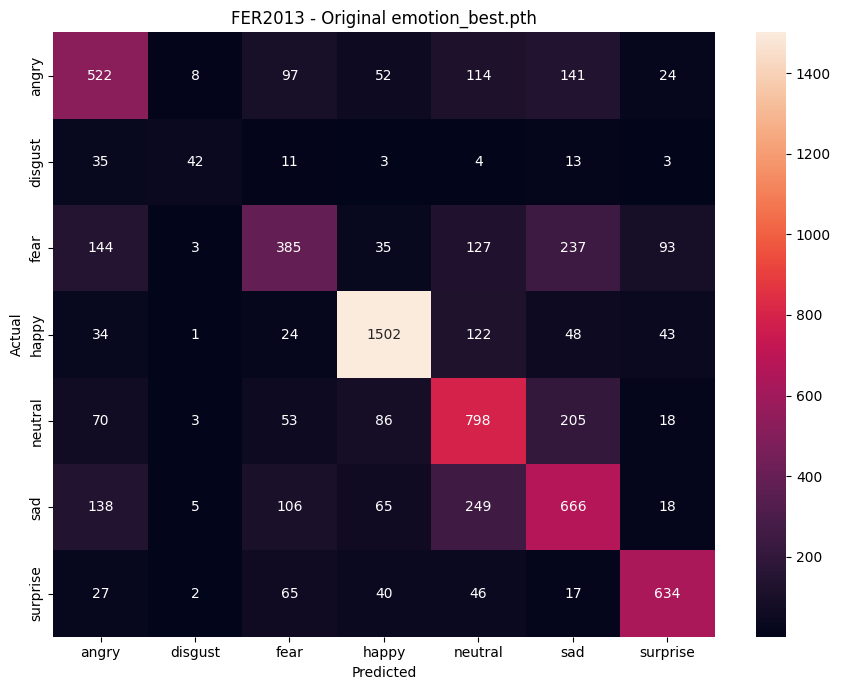

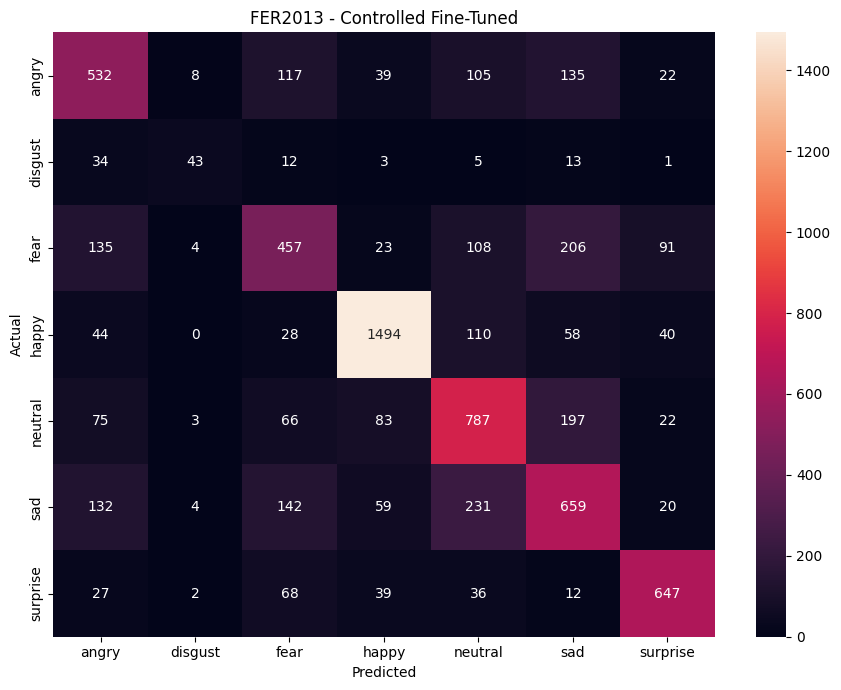



COMPARISON COMPLETE
Original Test Accuracy: 63.37%
Fine-Tuned Test Accuracy: 64.35%

Original Test Macro F1: 0.5963
Fine-Tuned Test Macro F1: 0.6093

Files saved to:
/content/drive/MyDrive/NeuroScreen/results/emotion_model_comparison.csv
/content/drive/MyDrive/NeuroScreen/results/emotion_per_class_comparison.csv
/content/drive/MyDrive/NeuroScreen/results/emotion_original_confusion_matrix.png
/content/drive/MyDrive/NeuroScreen/results/emotion_finetuned_confusion_matrix.png


In [ ]:
# ============================================================
# FER2013 - FINAL MODEL COMPARISON
# Original vs Controlled Fine-Tuned Model
# ============================================================

!pip -q install timm scikit-learn seaborn

import os
import zipfile
import shutil
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import timm

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from google.colab import drive


# ============================================================
# 1. DRIVE
# ============================================================

drive.mount('/content/drive')


# ============================================================
# 2. PATHS
# ============================================================

BASE = "/content/drive/MyDrive/NeuroScreen"

ZIP_PATH = BASE + "/datasets/FER2013.zip"

ORIGINAL_MODEL = BASE + "/models/emotion_best.pth"

FINETUNED_MODEL = (
    BASE
    + "/models/emotion_controlled_finetune_best.pth"
)

RESULTS_DIR = BASE + "/results"

LOCAL_DATASET = "/content/FER2013"

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)


# ============================================================
# 3. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ============================================================
# 4. VERIFY MODELS
# ============================================================

assert os.path.exists(
    ORIGINAL_MODEL
), "emotion_best.pth not found."

assert os.path.exists(
    FINETUNED_MODEL
), "emotion_controlled_finetune_best.pth not found."


# ============================================================
# 5. EXTRACT DATASET
# ============================================================

if os.path.exists(LOCAL_DATASET):

    shutil.rmtree(
        LOCAL_DATASET
    )

os.makedirs(
    LOCAL_DATASET
)

with zipfile.ZipFile(
    ZIP_PATH,
    "r"
) as z:

    z.extractall(
        LOCAL_DATASET
    )

TEST_DIR = LOCAL_DATASET + "/test"


# ============================================================
# 6. TRANSFORM
# ============================================================

test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],

        [0.229, 0.224, 0.225]
    )
])


# ============================================================
# 7. DATASET
# ============================================================

test_dataset = datasets.ImageFolder(

    TEST_DIR,

    transform=test_transform
)

classes = test_dataset.classes

print("\nClasses:")

for i, c in enumerate(classes):

    print(
        i,
        "=",
        c
    )

print(
    "\nTest images:",
    len(test_dataset)
)


# ============================================================
# 8. DATALOADER
# ============================================================

test_loader = DataLoader(

    test_dataset,

    batch_size=64,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


# ============================================================
# 9. MODEL
# ============================================================

def load_model(path):

    model = timm.create_model(

        "efficientnet_b0",

        pretrained=False,

        num_classes=7
    )

    checkpoint = torch.load(

        path,

        map_location=DEVICE
    )

    if (
        isinstance(checkpoint, dict)
        and "model_state_dict" in checkpoint
    ):

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

    else:

        model.load_state_dict(
            checkpoint
        )

    model.to(DEVICE)

    model.eval()

    return model


# ============================================================
# 10. PREDICTION FUNCTION
# ============================================================

def get_predictions(model):

    all_labels = []

    all_predictions = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            outputs = model(
                images
            )

            predictions = (
                outputs.argmax(
                    dim=1
                )
                .cpu()
                .numpy()
            )

            all_predictions.extend(
                predictions
            )

            all_labels.extend(
                labels.numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


# ============================================================
# 11. ORIGINAL MODEL
# ============================================================

print("\nEvaluating ORIGINAL model...")

original_model = load_model(
    ORIGINAL_MODEL
)

y_true, original_pred = get_predictions(
    original_model
)


# ============================================================
# 12. FINE-TUNED MODEL
# ============================================================

print("Evaluating CONTROLLED FINE-TUNED model...")

finetuned_model = load_model(
    FINETUNED_MODEL
)

_, finetuned_pred = get_predictions(
    finetuned_model
)


# ============================================================
# 13. OVERALL METRICS
# ============================================================

def calculate_metrics(
    y_true,
    predictions
):

    precision, recall, f1, support = (
        precision_recall_fscore_support(

            y_true,

            predictions,

            labels=list(range(7)),

            zero_division=0
        )
    )

    return {

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Macro Precision":
            precision.mean(),

        "Macro Recall":
            recall.mean(),

        "Macro F1":
            f1.mean(),

        "Weighted Precision":
            np.average(
                precision,
                weights=support
            ),

        "Weighted Recall":
            np.average(
                recall,
                weights=support
            ),

        "Weighted F1":
            np.average(
                f1,
                weights=support
            )
    }


original_metrics = calculate_metrics(
    y_true,
    original_pred
)

finetuned_metrics = calculate_metrics(
    y_true,
    finetuned_pred
)


# ============================================================
# 14. PRINT OVERALL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Metric":
        list(original_metrics.keys()),

    "Original":
        list(original_metrics.values()),

    "Controlled Fine-Tuned":
        list(finetuned_metrics.values())
})

comparison["Difference"] = (
    comparison["Controlled Fine-Tuned"]
    -
    comparison["Original"]
)

print("\n")
print("=" * 70)
print("OVERALL TEST COMPARISON")
print("=" * 70)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 15. PER-CLASS METRICS
# ============================================================

orig_precision, orig_recall, orig_f1, support = (
    precision_recall_fscore_support(

        y_true,

        original_pred,

        labels=list(range(7)),

        zero_division=0
    )
)

fine_precision, fine_recall, fine_f1, _ = (
    precision_recall_fscore_support(

        y_true,

        finetuned_pred,

        labels=list(range(7)),

        zero_division=0
    )
)

per_class = pd.DataFrame({

    "Emotion":
        classes,

    "Original Precision":
        orig_precision,

    "FineTuned Precision":
        fine_precision,

    "Original Recall":
        orig_recall,

    "FineTuned Recall":
        fine_recall,

    "Original F1":
        orig_f1,

    "FineTuned F1":
        fine_f1,

    "Support":
        support
})

print("\n")
print("=" * 70)
print("PER-CLASS TEST COMPARISON")
print("=" * 70)

print(
    per_class.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# 16. CLASSIFICATION REPORTS
# ============================================================

print("\n")
print("=" * 70)
print("ORIGINAL MODEL CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(

        y_true,

        original_pred,

        target_names=classes,

        digits=4,

        zero_division=0
    )
)


print("\n")
print("=" * 70)
print("CONTROLLED FINE-TUNED CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(

        y_true,

        finetuned_pred,

        target_names=classes,

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 17. CONFUSION MATRICES
# ============================================================

cm_original = confusion_matrix(
    y_true,
    original_pred,
    labels=list(range(7))
)

cm_finetuned = confusion_matrix(
    y_true,
    finetuned_pred,
    labels=list(range(7))
)


# ============================================================
# ORIGINAL CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(

    cm_original,

    annot=True,

    fmt="d",

    xticklabels=classes,

    yticklabels=classes
)

plt.title(
    "FER2013 - Original emotion_best.pth"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

original_cm_path = (
    RESULTS_DIR
    + "/emotion_original_confusion_matrix.png"
)

plt.savefig(
    original_cm_path,
    dpi=200
)

plt.show()


# ============================================================
# FINE-TUNED CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(9, 7)
)

sns.heatmap(

    cm_finetuned,

    annot=True,

    fmt="d",

    xticklabels=classes,

    yticklabels=classes
)

plt.title(
    "FER2013 - Controlled Fine-Tuned"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.tight_layout()

finetuned_cm_path = (
    RESULTS_DIR
    + "/emotion_finetuned_confusion_matrix.png"
)

plt.savefig(
    finetuned_cm_path,
    dpi=200
)

plt.show()


# ============================================================
# 18. SAVE CSV
# ============================================================

comparison_path = (
    RESULTS_DIR
    + "/emotion_model_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)


per_class_path = (
    RESULTS_DIR
    + "/emotion_per_class_comparison.csv"
)

per_class.to_csv(
    per_class_path,
    index=False
)


# ============================================================
# 19. SAVE JSON
# ============================================================

summary = {

    "original_model":
        original_metrics,

    "controlled_finetuned_model":
        finetuned_metrics,

    "test_samples":
        len(y_true)
}

with open(

    RESULTS_DIR
    + "/emotion_model_comparison.json",

    "w"

) as f:

    json.dump(
        summary,
        f,
        indent=4
    )


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("COMPARISON COMPLETE")
print("=" * 70)

print(
    f"Original Test Accuracy: "
    f"{original_metrics['Accuracy']*100:.2f}%"
)

print(
    f"Fine-Tuned Test Accuracy: "
    f"{finetuned_metrics['Accuracy']*100:.2f}%"
)

print()

print(
    f"Original Test Macro F1: "
    f"{original_metrics['Macro F1']:.4f}"
)

print(
    f"Fine-Tuned Test Macro F1: "
    f"{finetuned_metrics['Macro F1']:.4f}"
)

print("\nFiles saved to:")

print(comparison_path)

print(per_class_path)

print(original_cm_path)

print(finetuned_cm_path)